# Pronóstico de ventas por SKU
## Parte 4: test

¿Cuánto erra de verdad el modelo elegido en cada SKU, en meses que no se usaron para elegirlo?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from funciones import *

In [2]:
ventas = cargar_ventas()
skus = ["A", "B", "C", "D", "E"]
cortes_validacion = pd.date_range("2022-12-01", "2024-08-01", freq="MS")
cortes_test = pd.date_range("2024-11-01", "2025-02-01", freq="MS")

In [3]:
elegido = {"A": "Seasonal Naive", "B": "Media M3", "C": "Media", "D": "Media", "E": "Holt-Winters"}

modelos = {
    "A": {"Seasonal Naive": seasonal_naive, "Naive": naive},
    "B": {"Media M3": media_movil_3, "Naive": naive},
    "C": {"Media": media, "Naive": naive},
    "D": {"Media": media, "Naive": naive},
    "E": {"Holt-Winters": holt_winters, "Naive": naive},
}

In [7]:
test = []
for s in skus:
    test.append(walk_forward(ventas, [s], modelos[s], cortes_test))

test = pd.concat(test)
test["MASE"] = test["ErrorAbs"] / test["Escala"]

## Resultados en test

In [8]:
test.groupby(["SKU", "Modelo"]).apply(metricas).round(2)

MAE  MASE  Sesgo
SKU Modelo                            
A   Naive           15.17  1.09  11.83
    Seasonal Naive  12.00  0.86 -12.00
B   Media M3        18.11  0.74  17.33
    Naive           21.58  0.89  17.92
C   Media            5.72  0.68   3.49
    Naive            8.00  0.96   1.67
D   Media           31.09  1.00  30.51
    Naive           26.58  0.86   6.08
E   Holt-Winters    18.79  0.86  12.81
    Naive           27.83  1.28  22.00

- E: Holt-Winters erra mucho menos que el Naive (0.86 contra 1.28). Se mantiene.
- A: el Seasonal Naive (0.86) le gana al Naive (1.09), pero subestima 12 unidades por mes: A vendió más que el año anterior y copiar el año anterior quedó corto.
- B: la media móvil de 3 (0.74) le gana al Naive (0.89). Los dos sobreestiman unas 17 unidades: después de los picos de mayo y noviembre 2024, B bajó.
- C: la media (0.68) le gana al Naive (0.96), con sesgo bajo.
- D: la media (1.00) pierde contra el Naive (0.86) y sobreestima 30 unidades por mes. Es el riesgo que ya habíamos visto: la media arrastra niveles viejos y D viene más bajo. Por la regla fijada no se cambia, pero hay que tenerlo en cuenta para el pronóstico.

## Test contra validación

Si el error en test es mucho mayor que en validación, la validación era optimista.

In [9]:
validacion = []
for s in skus:
    validacion.append(walk_forward(ventas, [s], {elegido[s]: modelos[s][elegido[s]]}, cortes_validacion))

validacion = pd.concat(validacion)
validacion["MASE"] = validacion["ErrorAbs"] / validacion["Escala"]
validacion["Peso"] = validacion["Corte"].rank(method="dense")

def mase_ponderado(g):
    return (g["MASE"] * g["Peso"]).sum() / g["Peso"].sum()

elegidos_test = test[test["Modelo"] == test["SKU"].map(elegido)]

pd.DataFrame({
    "Modelo": elegido,
    "Validación (igual peso)": validacion.groupby("SKU")["MASE"].mean(),
    "Validación (peso lineal)": validacion.groupby("SKU").apply(mase_ponderado),
    "Test": elegidos_test.groupby("SKU")["MASE"].mean(),
}).round(2)

,Modelo,Validación (igual peso),Validación (peso lineal),Test
A,Seasonal Naive,0.84,0.87,0.86
B,Media M3,0.87,0.92,0.74
C,Media,1.07,0.98,0.68
D,Media,1.27,0.99,1.00
E,Holt-Winters,1.66,1.47,0.86


- En A y D el error del test es parecido al de validación.
- En B, C y E el test da menos error que la validación. No es que la validación fuera pesimista por mal diseño: la validación incluye el salto de E de julio 2023 y el período anómalo de D, y en el test no hubo saltos de ese tamaño.
- Con solo 12 pronósticos por SKU, el test también es ruidoso. Para estimar el error esperado conviene usar el más alto de los dos.

## Por corte y horizonte (MASE del modelo elegido)

In [10]:
elegidos_test.pivot_table(index=["SKU", "Corte"], columns="Horizonte", values="MASE").round(2)

Horizonte          1     2     3
SKU Corte                       
A   2024-11-01  2.37  0.58  0.72
    2024-12-01  0.58  0.72  0.29
    2025-01-01  0.72  0.29  1.72
    2025-02-01  0.29  1.73  0.36
B   2024-11-01  0.82  0.57  1.15
    2024-12-01  0.24  0.81  1.09
    2025-01-01  1.17  1.46  0.68
    2025-02-01  0.59  0.19  0.14
C   2024-11-01  1.03  0.18  0.91
    2024-12-01  0.16  0.87  0.87
    2025-01-01  0.87  0.87  0.44
    2025-02-01  0.86  0.46  0.70
D   2024-11-01  0.11  1.64  0.70
    2024-12-01  1.64  0.70  1.80
    2025-01-01  0.66  1.74  0.43
    2025-02-01  1.73  0.42  0.45
E   2024-11-01  0.93  0.20  0.05
    2024-12-01  0.71  0.55  0.85
    2025-01-01  0.14  1.25  1.15
    2025-02-01  1.34  1.24  1.92

- No hay un modelo que falle siempre a 3 meses. Los errores grandes aparecen en meses puntuales, desde distintos cortes y horizontes.
- En E, el último corte (febrero 2025) es el peor en los tres horizontes (1.34, 1.24 y 1.92): no anticipó la caída de marzo a mayo.

## Por mes pronosticado

Error promedio en unidades (pronóstico − real). Cada mes se pronostica desde hasta tres cortes distintos. Negativo significa que el modelo se quedó corto.

In [11]:
elegidos_test.pivot_table(index="SKU", columns="Fecha", values="Error").round(1)

Fecha,2024-12-01,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01
SKU,,,,,,
A,-33.0,-8.0,-10.0,-4.0,-24.0,-5.0
B,19.7,9.8,25.4,25.7,6.0,3.3
C,8.5,1.4,7.4,7.3,-3.8,-5.8
D,-3.5,50.5,21.2,54.7,13.3,14.1
E,19.9,-9.9,-5.4,25.2,26.2,41.8


- A se quedó corto todos los meses, sobre todo en diciembre (−33) y abril (−24).
- D se pasó casi todos los meses, sobre todo en enero (+50) y marzo (+55), que fueron meses muy bajos (30 y 25 unidades).
- E se pasó en marzo, abril y mayo (+25, +26 y +42): las ventas bajaron de 160 en febrero a 116 en mayo, por debajo de mayo 2024 (129).

## Victorias contra el Naive

En cuántos de los 12 pronósticos el modelo elegido tuvo menos error que el Naive. Como los pronósticos se solapan, contar victorias muestra si la ventaja es pareja o depende de pocos meses.

In [12]:
errores = test.pivot_table(index=["SKU", "Corte", "Horizonte"], columns="Modelo", values="ErrorAbs")

for s in skus:
    e = errores.loc[s]
    victorias = (e[elegido[s]] < e["Naive"]).sum()
    empates = (e[elegido[s]] == e["Naive"]).sum()
    print(f"{s}: {elegido[s]} gana {victorias} de 12 (empates: {empates})")

A: Seasonal Naive gana 7 de 12 (empates: 0)
B: Media M3 gana 5 de 12 (empates: 1)
C: Media gana 7 de 12 (empates: 0)
D: Media gana 6 de 12 (empates: 0)
E: Holt-Winters gana 10 de 12 (empates: 0)


- E: Holt-Winters gana en 10 de 12.
- A y C ganan en 7 de 12, y D en 6: la ventaja es chica o, en D, no existe.
- B gana solo en 5 de 12, aunque tiene menor MASE: su ventaja viene de pocos meses donde el Naive erró por mucho.

## Pronósticos de cada corte contra lo real

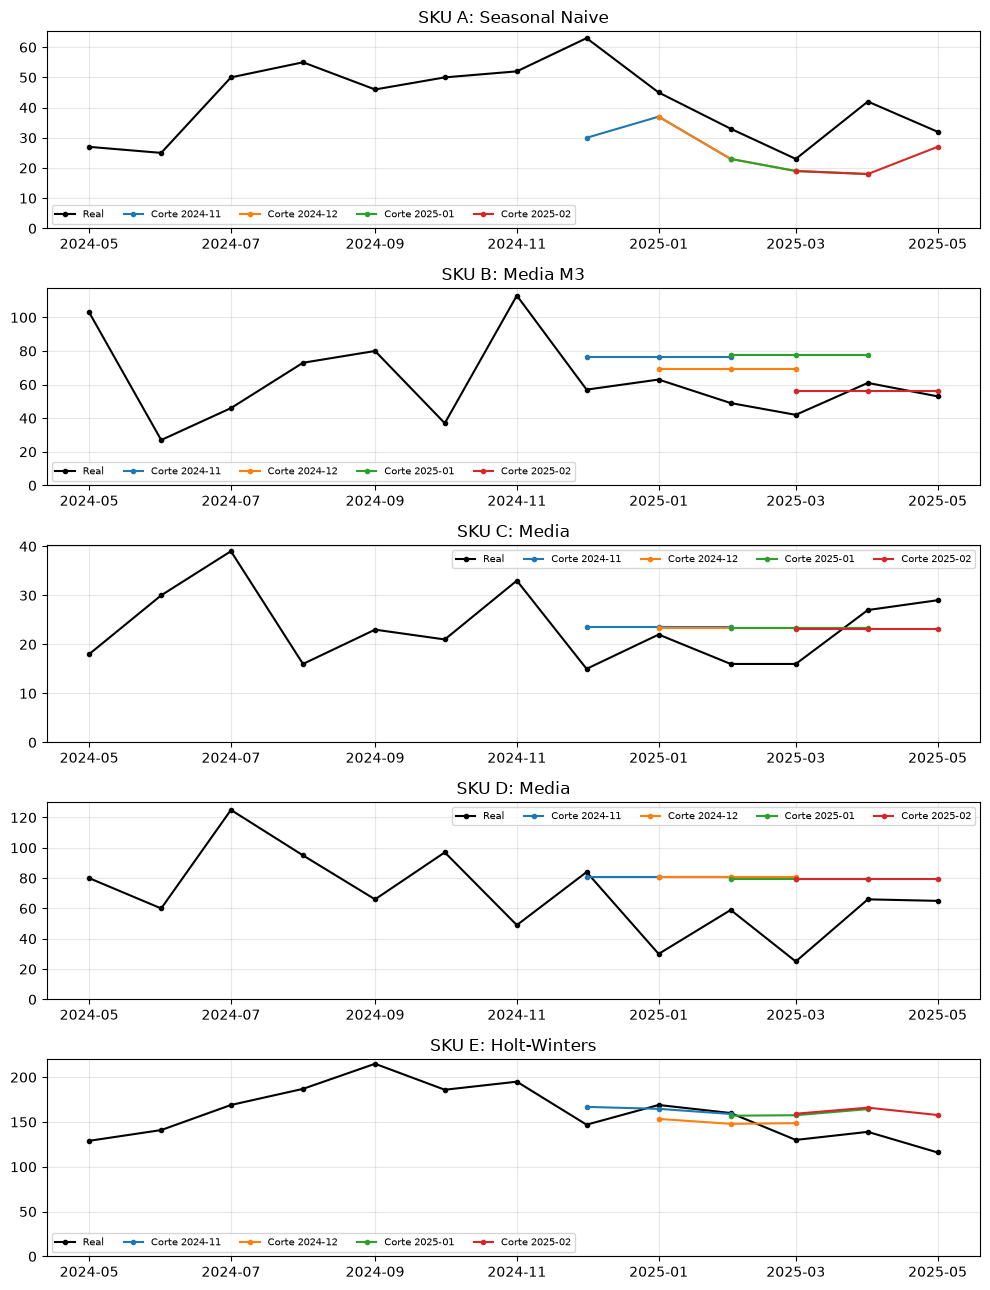

In [13]:
fig, axes = plt.subplots(5, 1, figsize=(10, 13))

for i, s in enumerate(skus):
    axes[i].plot(ventas.loc["2024-05-01":, s], color="black", marker="o", markersize=3, label="Real")
    for corte in cortes_test:
        p = elegidos_test[(elegidos_test["SKU"] == s) & (elegidos_test["Corte"] == corte)]
        axes[i].plot(p["Fecha"], p["Pronostico"], marker="o", markersize=3, label=f"Corte {corte.strftime('%Y-%m')}")
    axes[i].set_title(f"SKU {s}: {elegido[s]}")
    axes[i].set_ylim(bottom=0)
    axes[i].grid(alpha=0.3)
    axes[i].legend(fontsize=7, ncol=5)

plt.tight_layout()
plt.show()

- A: todos los pronósticos quedan por debajo de lo real.
- B: los cortes de noviembre y enero arrastran el pico de noviembre 2024 (113) y quedan altos. El último corte ya se acomoda.
- D: la media queda cerca de 80 mientras las ventas de 2025 están entre 25 y 66.
- E: los pronósticos quedan entre 150 y 165, y en primavera las ventas bajan a 116.

## Conclusiones

- Se mantiene la selección: Seasonal Naive para A, media móvil de 3 para B, media para C y D, y Holt-Winters para E.
- E es el resultado más sólido: Holt-Winters le gana al Naive en el total y en 10 de 12 pronósticos.
- D es el punto débil: la media sobreestima unas 30 unidades por mes y pierde contra el Naive.
- Hay sesgos claros en tres SKUs: A se queda corto, y D y E se pasan en los últimos meses. Hay que tenerlos en cuenta al leer el pronóstico de junio a agosto.